In [1]:
"""Example usage of the ztf_fp_query module.

Workflow:
  1. submit()  — send coordinates to the IPAC forced-photometry service
  2. sync()    — pull completed results to local storage (run after jobs finish)
  3. ForcedPhotometry — load and work with the data
"""

import sys
import matplotlib.pyplot as plt
import numpy as np

sys.path.insert(0, '..')

from ztf_fp_query.submit import submit, query_recent_jobs, query_pending_jobs, recently_queried, currently_pending
from ztf_fp_query.sync import sync
from ztf_fp_query.forced_photometry import ForcedPhotometry

CasJobs will use the credentials from mast_dino_login.txt


In [2]:
# -----------------------------------------------------------------------
# 1. Submit a batch request
# -----------------------------------------------------------------------
ras  = [210.08983, 206.42724]
decs = [ -6.88676,  -8.13603]

# Check which positions actually need submitting
already_done    = recently_queried(ras, decs)
still_pending   = currently_pending(ras, decs)
needs_submit    = ~already_done & ~still_pending

if needs_submit.any():
    submit([r for r, s in zip(ras, needs_submit) if s],
           [d for d, s in zip(decs, needs_submit) if s])
    print('Submitted. The service will email you when jobs complete.')
else:
    print('All positions already submitted or pending.')

All positions already submitted or pending.


In [3]:
# -----------------------------------------------------------------------
# 2. Check job status
# -----------------------------------------------------------------------

print('\n--- Pending jobs ---')
print(query_pending_jobs())

print('\n--- Recent jobs ---')
print(query_recent_jobs())


--- Pending jobs ---
Empty DataFrame
Columns: [reqId, ra, dec, startJD, endJD, created, started, ended, machine, exitcode, lightcurve]
Index: []

--- Recent jobs ---
      reqId         ra        dec         startJD           endJD  \
0   4838848  210.08983   -6.88676  2458194.500000  2461179.020666   
1   4838849  206.42724   -8.13603  2458194.500000  2461179.020666   
2   4838850  206.36837  -11.49883  2458194.500000  2461179.020666   
3   4838851  206.02459  -10.85017  2458194.500000  2461179.020666   
4   4838852  202.57787  -12.91953  2458194.500000  2461179.020666   
5   4838853  201.65216   -8.89921  2458194.500000  2461179.020666   
6   4838854  201.10234  -13.00011  2458194.500000  2461179.020666   
7   4838855  144.49788   26.27543  2458194.500000  2461179.020666   
8   4838856  143.95736    24.0227  2458194.500000  2461179.020666   
9   4838857  126.27485   26.70601  2458194.500000  2461179.020666   
10  4838858   69.28151  -18.49017  2458194.500000  2461179.020666   

    

In [4]:
# -----------------------------------------------------------------------
# 3. Sync completed results to local storage
# -----------------------------------------------------------------------

downloaded = sync()
print(f'\nDownloaded {len(downloaded)} new file(s).')


Downloaded 0 new file(s).


In [5]:
# -----------------------------------------------------------------------
# 4. Load a ForcedPhotometry object
# -----------------------------------------------------------------------

# By sky position (looks up the file via the local index)
fp = ForcedPhotometry(ra=126.27485, dec=26.70601)
print(fp)  # ForcedPhotometry(ra=..., dec=..., n_epochs=..., bands=[...])

# Or directly from a file path
fp = ForcedPhotometry.from_file(
    '/Users/adamboesky/Research/long_transients/Data/followup/126p274850_26p706012/zfps/'
    'batchfp_req0004838857_lc.txt'
)


ForcedPhotometry(ra=210.08983, dec=-6.88676, n_epochs=1082, bands=['ZTF_g', 'ZTF_i', 'ZTF_r'])


In [6]:
# -----------------------------------------------------------------------
# 5. Access the data
# -----------------------------------------------------------------------

# Full DataFrame — all ZFPS columns plus derived: snr, upperlim, mag, magerr
print(fp.df.columns.tolist())
print(fp.df.head())

# Which bands are present?
print(fp.bands)  # e.g. ['ZTF_g', 'ZTF_r', 'ZTF_i']

# Single-band slice
g_lc = fp.get_band('ZTF_g')
print(f'g-band epochs: {len(g_lc)}')

# Detections vs upper limits
detections  = fp.df[fp.df['upperlim'] == 0]
upper_limits = fp.df[fp.df['upperlim'] == 1]
print(f'Detections: {len(detections)}, Upper limits: {len(upper_limits)}')

# Quality filtering — done directly on the DataFrame
good = fp.df[(fp.df['procstatus'] == 0) & (fp.df['diffimgstatus'] == 1)]
print(f'Good-quality epochs: {len(good)}')

# High-SNR g-band detections
bright_g = fp.get_band('ZTF_g')
bright_g = bright_g[(bright_g['upperlim'] == 0) & (bright_g['snr'] > 10)]
print(f'High-SNR g-band epochs: {len(bright_g)}')

['sindex', 'field', 'ccdid', 'qid', 'filter', 'pid', 'infobitssci', 'sciinpseeing', 'scibckgnd', 'scisigpix', 'zpmaginpsci', 'zpmaginpsciunc', 'zpmaginpscirms', 'clrcoeff', 'clrcoeffunc', 'ncalmatches', 'exptime', 'adpctdif1', 'adpctdif2', 'diffmaglim', 'zpdiff', 'programid', 'jd', 'rfid', 'diffimgstatus', 'forcediffimflux', 'forcediffimfluxunc', 'forcediffimsnr', 'forcediffimchisq', 'forcediffimfluxap', 'forcediffimfluxuncap', 'forcediffimsnrap', 'aperturecorr', 'dnearestrefsrc', 'nearestrefmag', 'nearestrefmagunc', 'nearestrefchi', 'nearestrefsharp', 'refjdstart', 'refjdend', 'procstatus', 'snr', 'upperlim', 'mag', 'magerr']
   sindex  field  ccdid  qid filter           pid  infobitssci  sciinpseeing  \
0       0    374     14    2  ZTF_g  449355605315            0        2.6424   
1       1    374     14    2  ZTF_g  452321215315            0        2.5056   
2       2    374     14    2  ZTF_g  452368435315            0        2.2972   
3       3    374     14    2  ZTF_r  46334770

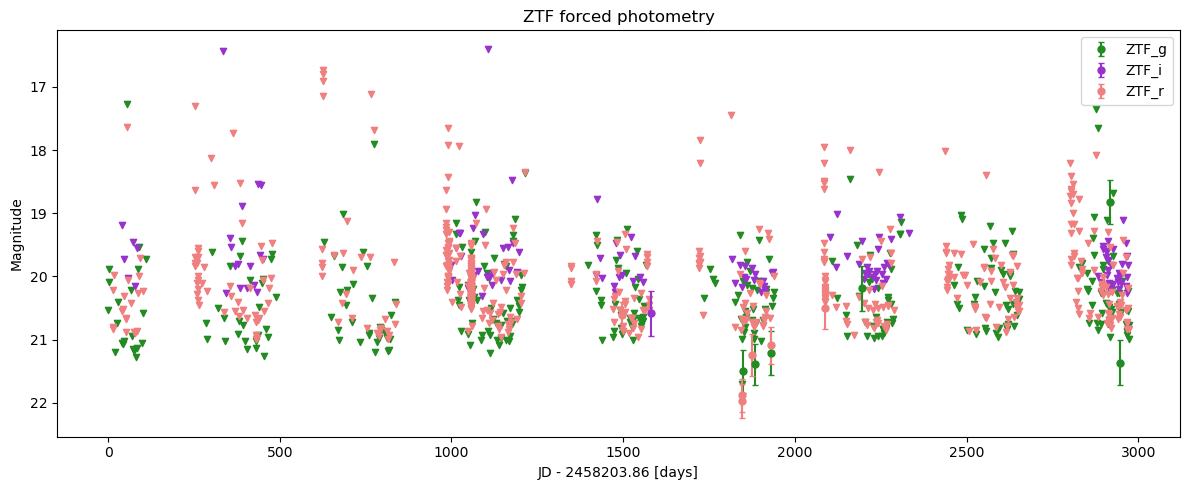

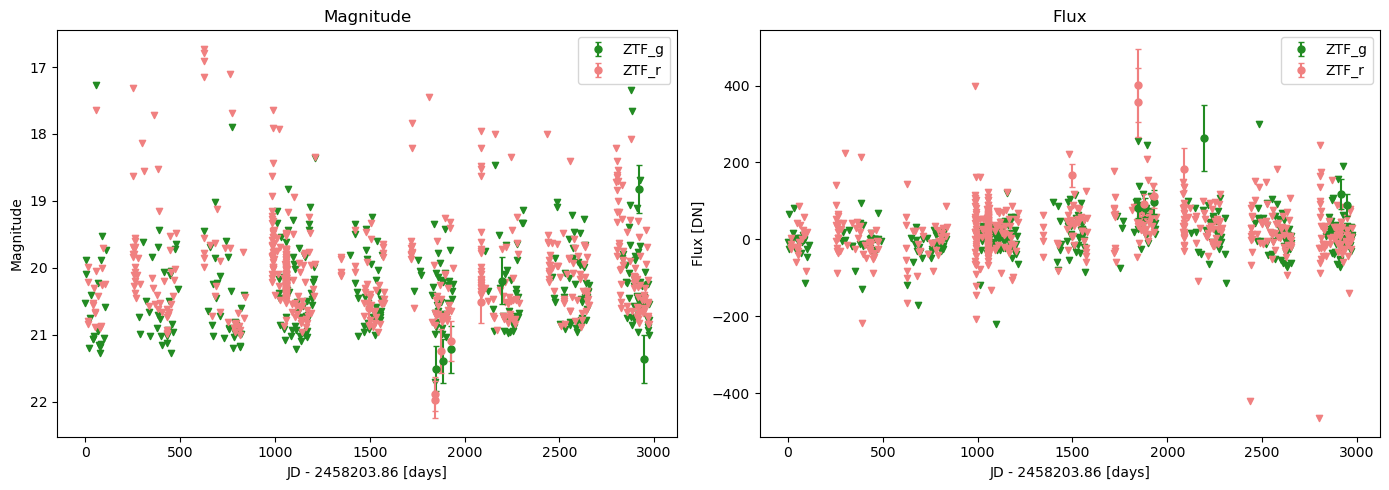

In [7]:
# -----------------------------------------------------------------------
# 6. Plot
# -----------------------------------------------------------------------

# Default: magnitude vs time, all bands
fig, ax = plt.subplots(figsize=(12, 5))
fp.plot(ax=ax)
ax.set_title('ZTF forced photometry') 

plt.tight_layout()
plt.show()

# Flux, g and r only, custom time offset
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

fp.plot(ax=axes[0], y_units='mag', bands=['ZTF_g', 'ZTF_r'])
axes[0].set_title('Magnitude')

fp.plot(ax=axes[1], y_units='flux', bands=['ZTF_g', 'ZTF_r'])
axes[1].set_title('Flux')

plt.tight_layout()
plt.show()

=== Full baseline stack ===
            flux  flux_err        snr        mag   mag_err  upperlim  n_epochs
band                                                                          
ZTF_g  12.774589  1.915282   6.669822  23.384560  0.162778         0       339
ZTF_i  19.306347  2.781446   6.941118  22.176044  0.156416         0       143
ZTF_r  18.550855  1.709514  10.851540  22.892628  0.100050         0       600

=== Pre-event baseline (first 200 days), g + r ===
           flux  flux_err       snr        mag  mag_err  upperlim  n_epochs
band                                                                       
ZTF_g -8.649986  6.267880 -1.380050  22.422441      NaN         1        21
ZTF_r -1.186816  7.493192 -0.158386  22.101763      NaN         1        20

30-day rolling:  250 stacked points
10-image rolling: 184 stacked points


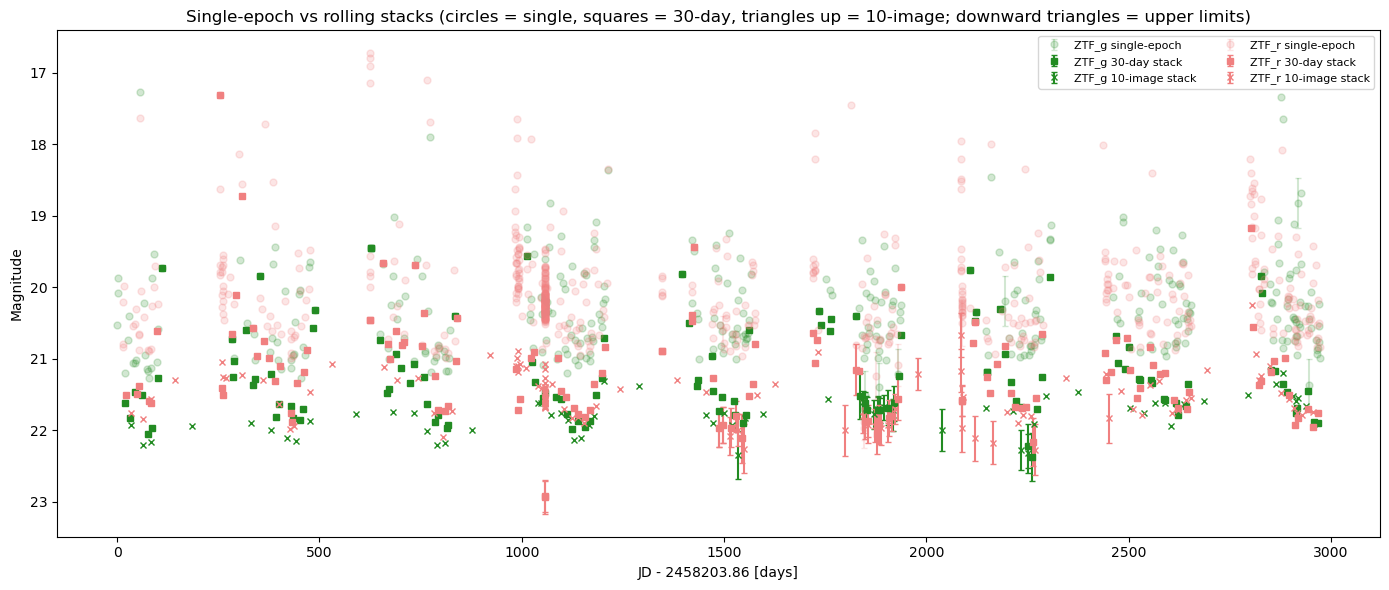

In [22]:
# -----------------------------------------------------------------------
# 7. Stacking
# -----------------------------------------------------------------------

print('=== Full baseline stack ===')
print(fp.stack())

jd_min = fp.df['jd'].min()
print('\n=== Pre-event baseline (first 200 days), g + r ===')
print(fp.stack(jd_min=jd_min, jd_max=jd_min + 200, bands=['ZTF_g', 'ZTF_r']))

window_days = 30
window_imgs = 10

rolled_days = fp.rolling_stack(window=window_days, bands=['ZTF_g', 'ZTF_r'], window_unit='days')
rolled_imgs = fp.rolling_stack(window=window_imgs, bands=['ZTF_g', 'ZTF_r'], window_unit='images')

print(f'\n{window_days}-day rolling:  {len(rolled_days)} stacked points')
print(f'{window_imgs}-image rolling: {len(rolled_imgs)} stacked points')


# -----------------------------------------------------------------------
# Comparison plot: single-epoch, day-windowed, image-windowed on one axis
# -----------------------------------------------------------------------

bands  = ['ZTF_g', 'ZTF_r']
colors = {'ZTF_g': 'forestgreen', 'ZTF_r': 'lightcoral'}
jd0    = fp.df['jd'].min()

# marker / style config per series
STYLES = {
    'single': dict(fmt='o',  markersize=5, capsize=2, alpha=0.2),
    'days':   dict(fmt='s',  markersize=5, capsize=2),
    'images': dict(fmt='x',  markersize=5, capsize=2),
}

fig, ax = plt.subplots(figsize=(14, 6))

for band in bands:
    color = colors[band]

    # --- single-epoch detections ---
    lc     = fp.get_band(band)
    # not_ul = lc['upperlim'] == 0
    ax.errorbar(
        lc['jd'] - jd0, lc['mag'], yerr=lc['magerr'],
        color=color, label=f'{band} single-epoch', **STYLES['single'],
    )

    # --- 30-day rolling stack ---
    grp    = rolled_days[rolled_days['band'] == band].sort_values('jd_center')
    not_ul = grp['upperlim'] == 0
    ax.errorbar(
        grp['jd_center'] - jd0, grp['mag'], yerr=grp['mag_err'],
        color=color, label=f'{band} 30-day stack', **STYLES['days'],
    )

    # --- 10-image rolling stack ---
    grp    = rolled_imgs[rolled_imgs['band'] == band].sort_values('jd_center')
    not_ul = grp['upperlim'] == 0
    ax.errorbar(
        grp['jd_center'] - jd0, grp['mag'], yerr=grp['mag_err'],
        color=color, label=f'{band} 10-image stack', **STYLES['images'],
    )

ax.invert_yaxis()
ax.set_xlabel(f'JD - {jd0:.2f} [days]')
ax.set_ylabel('Magnitude')
ax.set_title('Single-epoch vs rolling stacks (circles = single, squares = 30-day, triangles up = 10-image; downward triangles = upper limits)')
ax.legend(fontsize=8, ncol=2)
plt.tight_layout()
plt.show()

=== Full baseline stack ===
            flux  flux_err        snr        mag   mag_err  upperlim  n_epochs
band                                                                          
ZTF_g  12.774589  1.915282   6.669822  23.384560  0.162778         0       339
ZTF_i  19.306347  2.781446   6.941118  22.176044  0.156416         0       143
ZTF_r  18.550855  1.709514  10.851540  22.892628  0.100050         0       600

=== Pre-event baseline (first 200 days), g + r ===
           flux  flux_err       snr        mag  mag_err  upperlim  n_epochs
band                                                                       
ZTF_g -8.649986  6.267880 -1.380050  22.422441      NaN         1        21
ZTF_r -1.186816  7.493192 -0.158386  22.101763      NaN         1        20

365-day rolling:  32 stacked points
60-image rolling: 28 stacked points


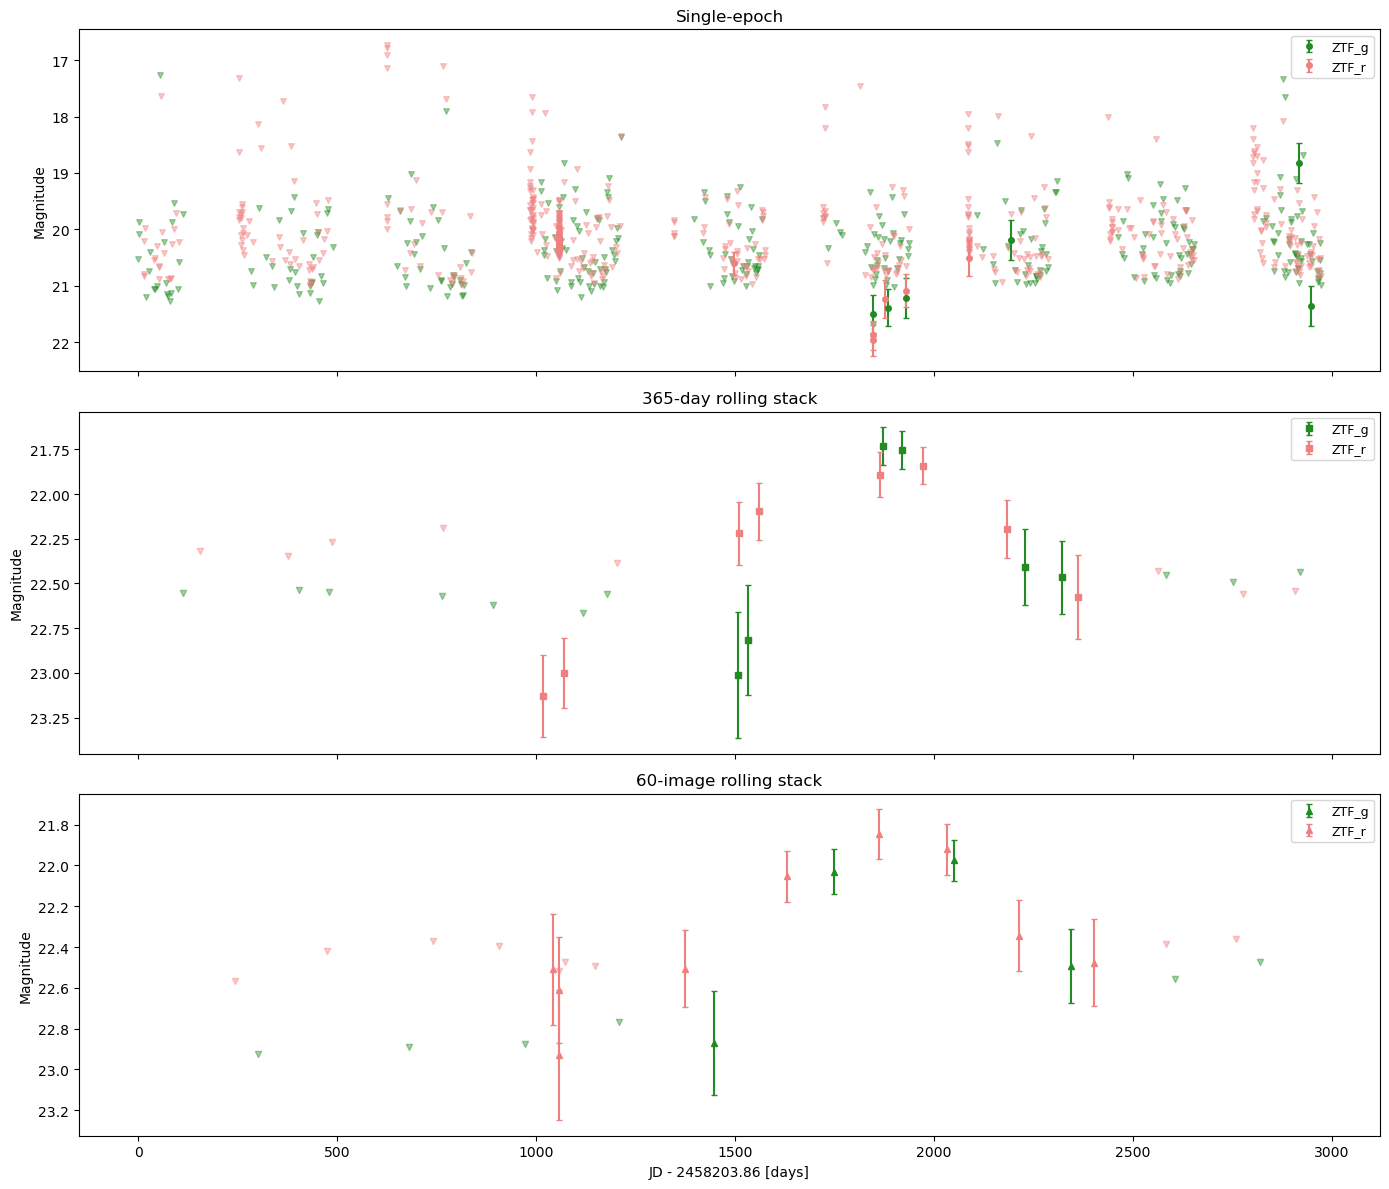

In [ ]:
# -----------------------------------------------------------------------
# 7. Stacking
# -----------------------------------------------------------------------

print('=== Full baseline stack ===')
print(fp.stack())

jd_min = fp.df['jd'].min()
print('\n=== Pre-event baseline (first 200 days), g + r ===')
print(fp.stack(jd_min=jd_min, jd_max=jd_min + 200, bands=['ZTF_g', 'ZTF_r']))

window_days = 365
window_imgs = 60

rolled_days = fp.rolling_stack(window=window_days, bands=['ZTF_g', 'ZTF_r'], window_unit='days')
rolled_imgs = fp.rolling_stack(window=window_imgs, bands=['ZTF_g', 'ZTF_r'], window_unit='images')

print(f'\n{window_days}-day rolling:  {len(rolled_days)} stacked points')
print(f'{window_imgs}-image rolling: {len(rolled_imgs)} stacked points')


# -----------------------------------------------------------------------
# Comparison plot: three vertically-stacked panels sharing x-axis
# -----------------------------------------------------------------------

bands  = ['ZTF_g', 'ZTF_r']
colors = {'ZTF_g': 'forestgreen', 'ZTF_r': 'lightcoral'}
jd0    = fp.df['jd'].min()

fig, axes = plt.subplots(3, 1, figsize=(14, 12), sharex=True)
titles = ['Single-epoch', f'{window_days}-day rolling stack', f'{window_imgs}-image rolling stack']

for ax, title in zip(axes, titles):
    ax.set_title(title)
    ax.set_ylabel('Magnitude')
    ax.invert_yaxis()

ax_single, ax_days, ax_imgs = axes

for band in bands:
    color = colors[band]

    # --- single-epoch ---
    lc     = fp.get_band(band)
    not_ul = lc['upperlim'] == 0
    ax_single.errorbar(
        lc['jd'][not_ul] - jd0, lc['mag'][not_ul], yerr=lc['magerr'][not_ul],
        fmt='o', markersize=4, capsize=2, color=color, label=band,
    )
    ax_single.scatter(
        lc['jd'][~not_ul] - jd0, lc['mag'][~not_ul],
        marker='v', s=16, color=color, alpha=0.4,
    )

    # --- day rolling stack ---
    grp    = rolled_days[rolled_days['band'] == band].sort_values('jd_center')
    not_ul = grp['upperlim'] == 0
    ax_days.errorbar(
        grp['jd_center'][not_ul] - jd0, grp['mag'][not_ul], yerr=grp['mag_err'][not_ul],
        fmt='s', markersize=5, capsize=2, color=color, label=band,
    )
    ax_days.scatter(
        grp['jd_center'][~not_ul] - jd0, grp['mag'][~not_ul],
        marker='v', s=20, color=color, alpha=0.4,
    )

    # --- image rolling stack ---
    grp    = rolled_imgs[rolled_imgs['band'] == band].sort_values('jd_center')
    not_ul = grp['upperlim'] == 0
    ax_imgs.errorbar(
        grp['jd_center'][not_ul] - jd0, grp['mag'][not_ul], yerr=grp['mag_err'][not_ul],
        fmt='^', markersize=5, capsize=2, color=color, label=band,
    )
    ax_imgs.scatter(
        grp['jd_center'][~not_ul] - jd0, grp['mag'][~not_ul],
        marker='v', s=20, color=color, alpha=0.4,
    )

for ax in axes:
    ax.legend(fontsize=9)

axes[-1].set_xlabel(f'JD - {jd0:.2f} [days]')
plt.tight_layout()
plt.show()